# E-Commerce Sales & Customer Analytics

## 1. Project Overview

This project analyzes real-world e-commerce transaction data to understand sales performance, customer purchasing behavior, and product trends.

## 2. Business Objectives

* Analyze sales and revenue trends.
* Identify top-performing products and markets.
* Understand customer purchasing behavior.
* Investigate data quality issues.
* Generate actionable business insights.

## 3. Tools & Technologies

* Python
* Pandas
* Jupyter Notebook
* MySQL
* Power BI

## 4. Dataset

The project uses the UCI Online Retail dataset, which contains transaction records from an online retail business.


In [1]:
import sys

print(sys.version)

3.14.2 (tags/v3.14.2:df79316, Dec  5 2025, 17:18:21) [MSC v.1944 64 bit (AMD64)]


In [2]:
%pip install numpy pandas matplotlib seaborn plotly scikit-learn openpyxl sqlalchemy pymysql mysql-connector-python

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

print("Pandas version:", pd.__version__)

Pandas version: 3.1.0


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn
import openpyxl
import sqlalchemy
import pymysql
import mysql.connector

print("All libraries imported successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.0
Scikit-learn: 1.9.1


## 5. Data Loading

The dataset is loaded into a Pandas DataFrame for further inspection and analysis.

The initial analysis will examine the dataset's structure, column names, data types, and data quality.


In [1]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/Online Retail.xlsx")

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

Dataset loaded successfully!
Rows and columns: (541909, 8)


## 6. Initial Data Inspection

This section examines the dataset's structure and identifies potential data quality issues before performing detailed analysis.


In [2]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display first 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# Check data types and missing values
print("\nDataset Information:")
df.info()

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## 7. Data Quality Assessment

### Objective

The objective of this section is to evaluate the quality and reliability of the transaction data before performing business analysis.

We will investigate:

* Missing values
* Duplicate records
* Data types
* Invalid or unusual quantities and prices
* Potential cancelled transactions

These checks will help us determine the appropriate data-cleaning strategy while preserving meaningful business information.


In [5]:
print("Missing values in each column:")
display(df.isnull().sum())

print("/nPercentage of Missing values:")
missing_percentage = (df.isnull().sum()/len(df))*100
display(missing_percentage.round(2))

print("/nTotal duplicate rows:")
print(df.duplicated().sum())

print("\nColumn Data Types:")
display(df.dtypes)

Missing values in each column:


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

/nPercentage of Missing values:


InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

/nTotal duplicate rows:
5268

Column Data Types:


InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

## 8. Quantity, Price and Cancellation Checks

### Objective

In this section, we will identify unusual transaction values, including negative or zero quantities, negative or zero unit prices, and invoices that may represent cancelled transactions.

Negative quantities may indicate product returns, while invoice numbers beginning with "C" may indicate cancellations. These records will be investigated before deciding how to handle them.


In [6]:
# Check unusual quantities
print("Negative Quantity Rows:", (df["Quantity"] < 0).sum())
print("Zero Quantity Rows:", (df["Quantity"] == 0).sum())

# Check unusual prices
print("Negative UnitPrice Rows:", (df["UnitPrice"] < 0).sum())
print("Zero UnitPrice Rows:", (df["UnitPrice"] == 0).sum())

# Check potential cancelled transactions
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")
print("Potential Cancellation Rows:", cancelled.sum())

Negative Quantity Rows: 10624
Zero Quantity Rows: 0
Negative UnitPrice Rows: 2
Zero UnitPrice Rows: 2515
Potential Cancellation Rows: 9288


## 9. Data Quality Findings

The initial data quality assessment identified missing values, duplicate records, and unusual transaction values.

Key findings:

* CustomerID is missing in approximately 24.93% of records.
* Description is missing in approximately 0.27% of records.
* The dataset contains 5,268 duplicate rows.
* A total of 10,624 rows have negative quantities.
* A total of 2,515 rows have zero unit prices.
* There are 2 rows with negative unit prices.
* A total of 9,288 invoices have invoice numbers beginning with "C", indicating potential cancellations.

These records require further investigation before cleaning. Missing customer IDs may limit customer-level analysis, while negative quantities and cancellation invoices may affect sales calculations.


In [7]:
# Inspect transactions with negative quantities
negative_quantity = df[df["Quantity"] < 0]

print("First 10 transactions with negative quantities:")
display(negative_quantity.head(10))

# Check how many negative-quantity rows have invoice numbers starting with C
print(
    "Negative quantity rows with cancellation invoice numbers:",
    negative_quantity["InvoiceNo"].astype(str).str.startswith("C").sum()
)

# Inspect transactions with negative unit prices
print("Transactions with negative unit prices:")
display(df[df["UnitPrice"] < 0])

First 10 transactions with negative quantities:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Negative quantity rows with cancellation invoice numbers: 9288
Transactions with negative unit prices:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [8]:
# Check whether all cancellation invoices have negative quantities
cancellation_rows = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Total cancellation invoice rows:", len(cancellation_rows))

print(
    "Cancellation rows with negative quantities:",
    (cancellation_rows["Quantity"] < 0).sum()
)

print(
    "Cancellation rows with zero or positive quantities:",
    (cancellation_rows["Quantity"] >= 0).sum()
)

# Check negative quantities without a cancellation invoice number
other_negative_rows = df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]

print(
    "Negative quantity rows without C invoice numbers:",
    len(other_negative_rows)
)

display(other_negative_rows.head(10))

Total cancellation invoice rows: 9288
Cancellation rows with negative quantities: 9288
Cancellation rows with zero or positive quantities: 0
Negative quantity rows without C invoice numbers: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


## 10. Data Cleaning Strategy

Based on the data quality assessment, the following cleaning strategy will be applied:

1. Preserve the original dataset for reference.
2. Remove exact duplicate records from the working copy.
3. Exclude invoices beginning with "C" from the regular sales dataset because they represent cancellation transactions.
4. Exclude records with negative quantities from regular sales calculations, while retaining the original data for further investigation.
5. Exclude records with negative unit prices from regular sales calculations because they represent unusual accounting adjustments.
6. Retain zero-unit-price records for initial investigation rather than automatically removing them.
7. Handle missing customer IDs carefully, since these records may still contribute to overall sales analysis.

These decisions will help create a reliable dataset for sales trends, product performance, and customer analytics.


In [9]:
# Create a separate working copy
df_clean = df.copy()

# Step 1: Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

# Step 2: Exclude cancellation invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Step 3: Exclude negative quantities
df_clean = df_clean[df_clean["Quantity"] > 0]

# Step 4: Exclude negative unit prices
df_clean = df_clean[df_clean["UnitPrice"] >= 0]

# Display results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())
print("Remaining negative quantities:", (df_clean["Quantity"] < 0).sum())
print("Remaining negative prices:", (df_clean["UnitPrice"] < 0).sum())

Original dataset shape: (541909, 8)
Cleaned dataset shape: (526052, 8)
Remaining duplicate rows: 0
Remaining negative quantities: 0
Remaining negative prices: 0


## 11. Data Cleaning Results

The original dataset contained 541,909 rows and 8 columns. After removing exact duplicate records, cancellation invoices, negative quantities, and negative unit prices, the cleaned dataset contains 526,052 rows and 8 columns.

The cleaned dataset has no remaining exact duplicate records, negative quantities, or negative unit prices. Zero-unit-price transactions and records with missing customer IDs have been retained for further analysis.

The cleaned dataset will be used for sales performance analysis, product analysis, and customer analytics.


In [10]:
# calculate total transaction value
df_clean["TotalPrice"] = df_clean['Quantity']*df_clean['UnitPrice']
display(df_clean.head())

#check the new column
print("Updated dataset shape:",df_clean.shape)
print("TotalPrice missing values:", df_clean["TotalPrice"].isnull().sum())

# Calculate overall sales value
print("Total Sales Value:", round(df_clean["TotalPrice"].sum(), 2))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Updated dataset shape: (526052, 9)
TotalPrice missing values: 0
Total Sales Value: 10642110.8


## 12. Exploratory Data Analysis (EDA)

### Objective

Exploratory Data Analysis helps identify patterns, trends, and relationships in the cleaned transaction data.

In this section, we will analyze:

* Monthly sales trends
* Top-selling products by quantity
* Highest-revenue products
* Sales by country
* Customer purchasing behavior

These insights will help us understand business performance and identify opportunities for improvement.


In [11]:
# Create a monthly sales summary
df_clean["InvoiceMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M")
)

monthly_sales = (
    df_clean.groupby("InvoiceMonth")["TotalPrice"]
    .sum()
    .reset_index()
)

monthly_sales["InvoiceMonth"] = (
    monthly_sales["InvoiceMonth"].astype(str)
)

monthly_sales.columns = ["Month", "TotalSales"]

print("Monthly Sales Summary:")
display(monthly_sales)

print("\nMonth with Highest Sales:")
display(
    monthly_sales.loc[
        monthly_sales["TotalSales"].idxmax()
    ]
)

Monthly Sales Summary:


,Month,TotalSales
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192



Month with Highest Sales:


Month            2011-11
TotalSales    1503866.78
Name: 11, dtype: object

## 13. Monthly Sales Trend — Key Insights

The monthly sales analysis shows noticeable variations in sales performance throughout the period.

* November 2011 recorded the highest monthly sales of £1,503,866.78.
* October 2011 was the second-highest month, with sales of £1,151,263.73.
* February 2011 recorded the lowest monthly sales of £522,545.56.
* Sales increased substantially from September through November 2011.

These findings highlight the importance of monitoring monthly sales trends to identify high-performing periods and investigate possible seasonal patterns.


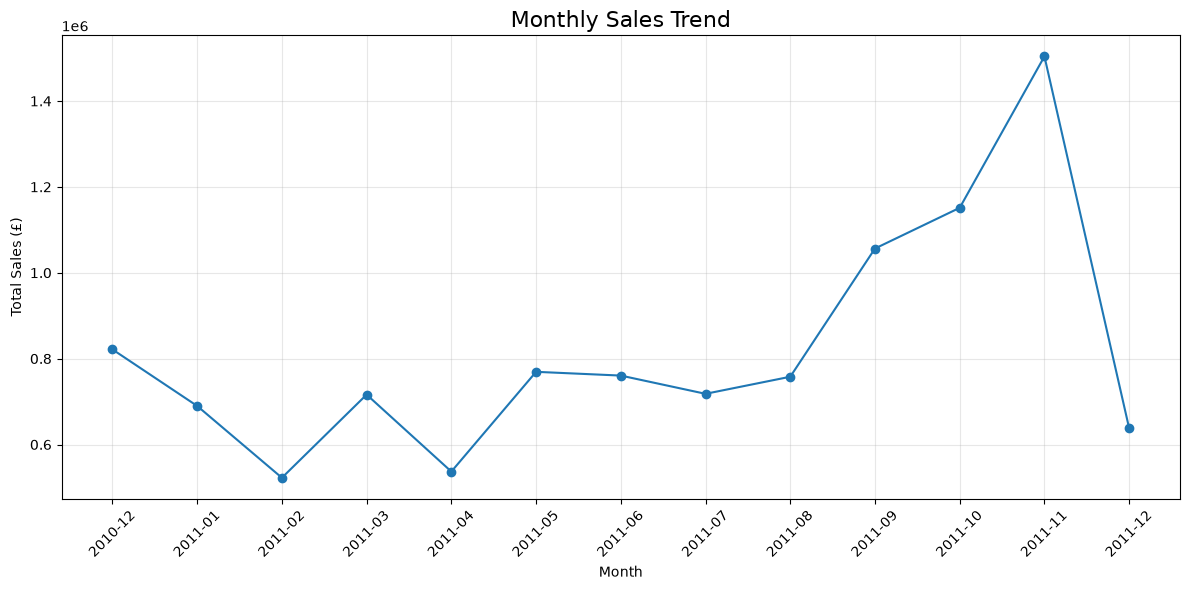

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["TotalSales"],
    marker="o"
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Top 10 Products by Sales

Identify the products that generate the highest sales revenue.


In [13]:
product_sales = df_clean.groupby("Description")["TotalPrice"].sum()

top_10_products = product_sales.nlargest(10)

top_10_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: TotalPrice, dtype: float64

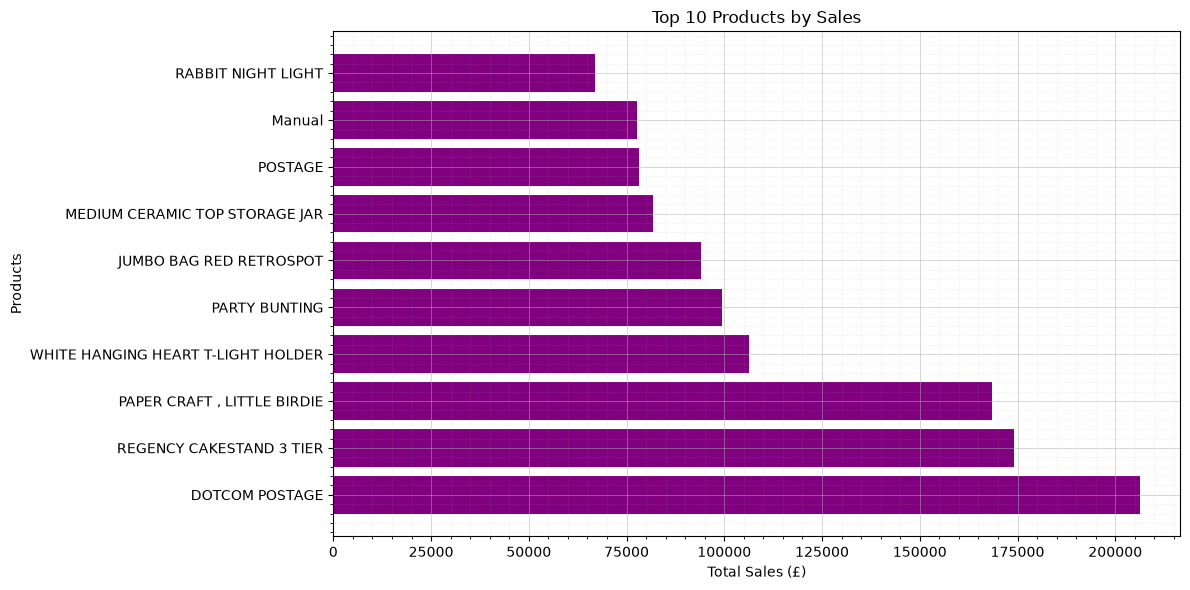

In [14]:
plt.figure(figsize=(12,6))

plt.barh(top_10_products.index,top_10_products.values , color = 'purple')
plt.xlabel("Total Sales (£)") 
plt.ylabel("Products") 
plt.title("Top 10 Products by Sales")
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.7, alpha=0.5)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

## Top 10 Countries by Sales

Analyze country-wise sales revenue to identify the top-performing markets.



In [15]:
country_sales = df_clean.groupby("Country")["TotalPrice"].sum()

top_10_countries = country_sales.nlargest(10)

top_10_countries

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: TotalPrice, dtype: float64

## Top 10 Countries by Sales


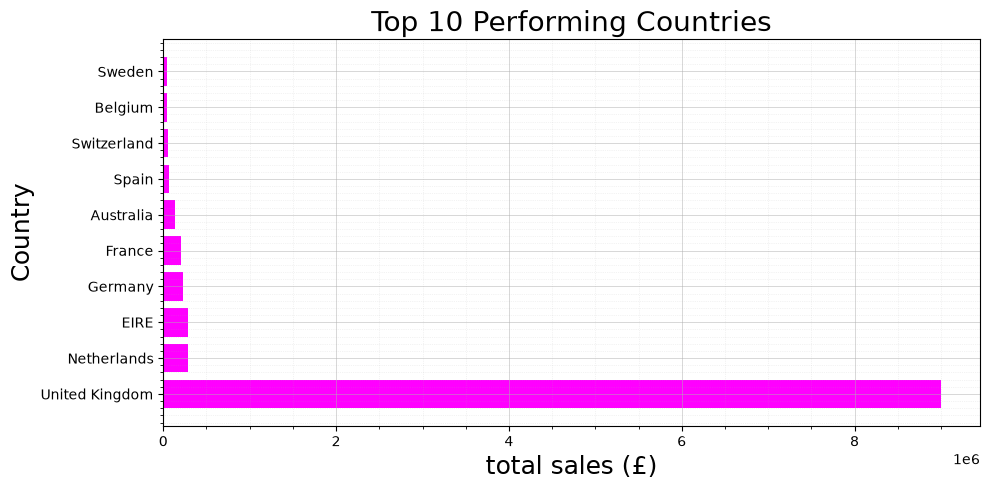

In [16]:
plt.figure(figsize=(10,5))

plt.barh(top_10_countries.index,top_10_countries.values, color='magenta')
plt.xlabel("total sales (£)",fontsize=18)
plt.ylabel("Country",fontsize=18)
plt.title("Top 10 Performing Countries",fontsize= 20)
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.7, alpha=0.5)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

## Top Customers by Sales


In [17]:
customer_sales = df_clean.groupby("CustomerID")["TotalPrice"].sum()

top_10_customers = customer_sales.nlargest(10)

top_10_customers

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: TotalPrice, dtype: float64

## Top Customers by Sales


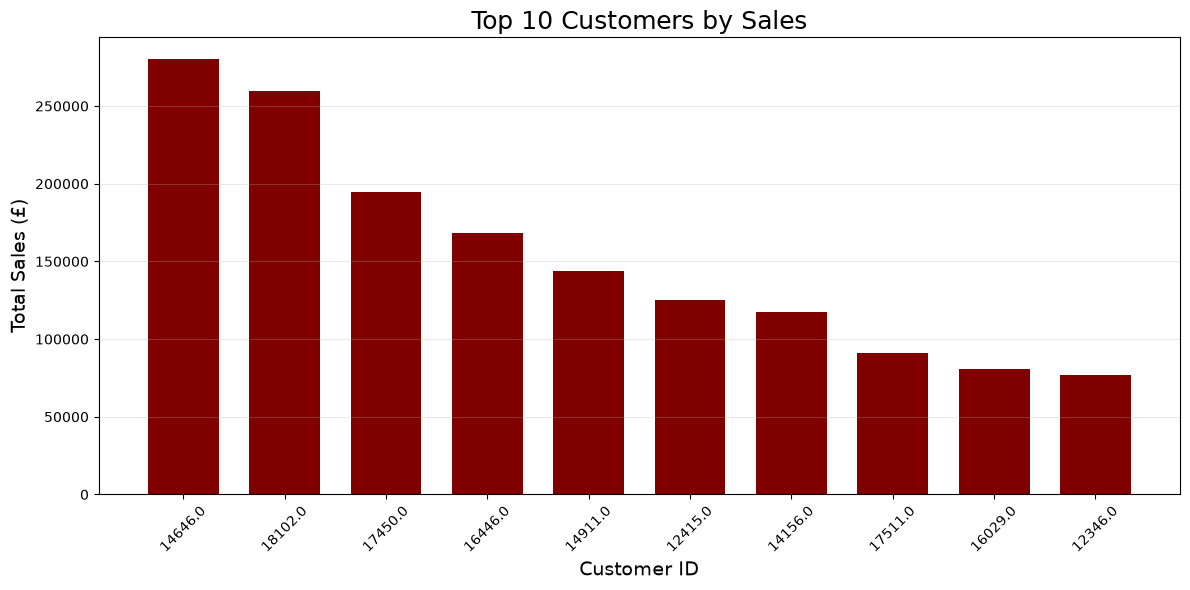

In [18]:
plt.figure(figsize=(12, 6))

plt.bar(top_10_customers.index.astype(str),
        top_10_customers.values,
        color='maroon',
        width=0.7)

plt.xlabel("Customer ID", fontsize=14)
plt.ylabel("Total Sales (£)", fontsize=14)
plt.title("Top 10 Customers by Sales", fontsize=18)

plt.xticks(rotation=45)
plt.minorticks_off()
plt.grid(axis='y', linestyle='-', linewidth=0.5, alpha=0.4)

plt.tight_layout()
plt.show()

## Customer Sales Insights

In [19]:
top_10_customers.head(5)

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
Name: TotalPrice, dtype: float64

The top 5 customers contribute significant sales to the business. Customer 14646 has the highest sales, followed by customers 18102 and 17450.

## Repeat vs One-time Customers

In [20]:
customer_orders = df_clean.dropna(subset=["CustomerID"]).groupby("CustomerID")["InvoiceNo"].nunique()

repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()

print("Repeat Customers:", repeat_customers)
print("One-time Customers:", one_time_customers)

Repeat Customers: 2845
One-time Customers: 1494


Repeat customers are higher in number than one-time customers, indicating that many customers made multiple purchases.


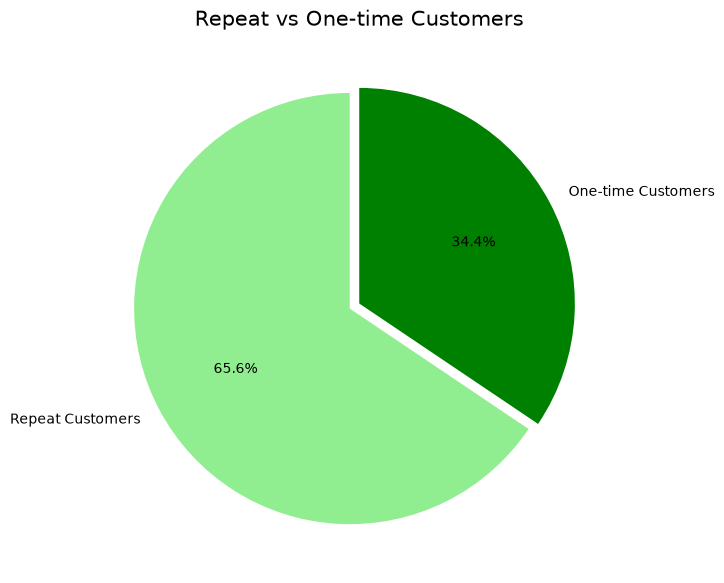

In [21]:
customer_types = ["Repeat Customers", "One-time Customers"]
customer_counts = [repeat_customers, one_time_customers]

plt.figure(figsize=(7, 7))

plt.pie(
    customer_counts,
    labels=customer_types,
    autopct="%1.1f%%",
    colors=["lightgreen", "green"],
    startangle=90,
    explode=(0.05, 0)
)

plt.title("Repeat vs One-time Customers", fontsize=15)
plt.show()

## Customer Purchase Behaviour Analysis

In [22]:
customer_orders.describe()

count    4339.000000
mean        4.271952
std         7.705493
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       210.000000
Name: InvoiceNo, dtype: float64

In [23]:
bins=[0,1,5,10,float('inf')]

order_groups = pd.cut(
    customer_orders,
    bins=bins,
    labels=["1", "2-5", "6-10", "11+"]
)


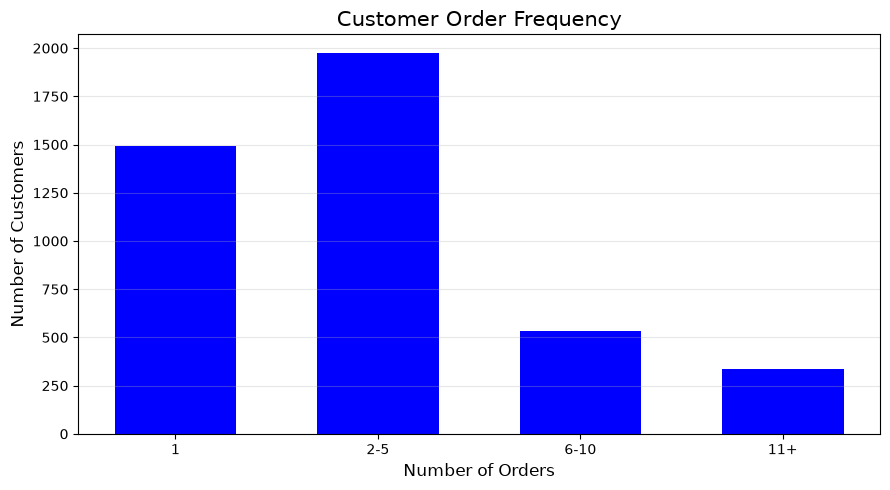

In [24]:
order_counts = order_groups.value_counts().sort_index()

plt.figure(figsize=(9, 5))

plt.bar(
    order_counts.index.astype(str),
    order_counts.values,
    color="blue",
    width=0.6
)

plt.xlabel("Number of Orders", fontsize=12)
plt.ylabel("Number of Customers", fontsize=12)
plt.title("Customer Order Frequency", fontsize=15)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Sales by Day of Week

In [25]:
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()

Day_sales = df_clean.groupby("DayOfWeek")["TotalPrice"].sum().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    fill_value=0)

Day_sales

DayOfWeek
Monday       1775782.071
Tuesday      2175700.511
Wednesday    1847074.380
Thursday     2199292.570
Friday       1837470.491
Saturday           0.000
Sunday        806790.781
Name: TotalPrice, dtype: float64

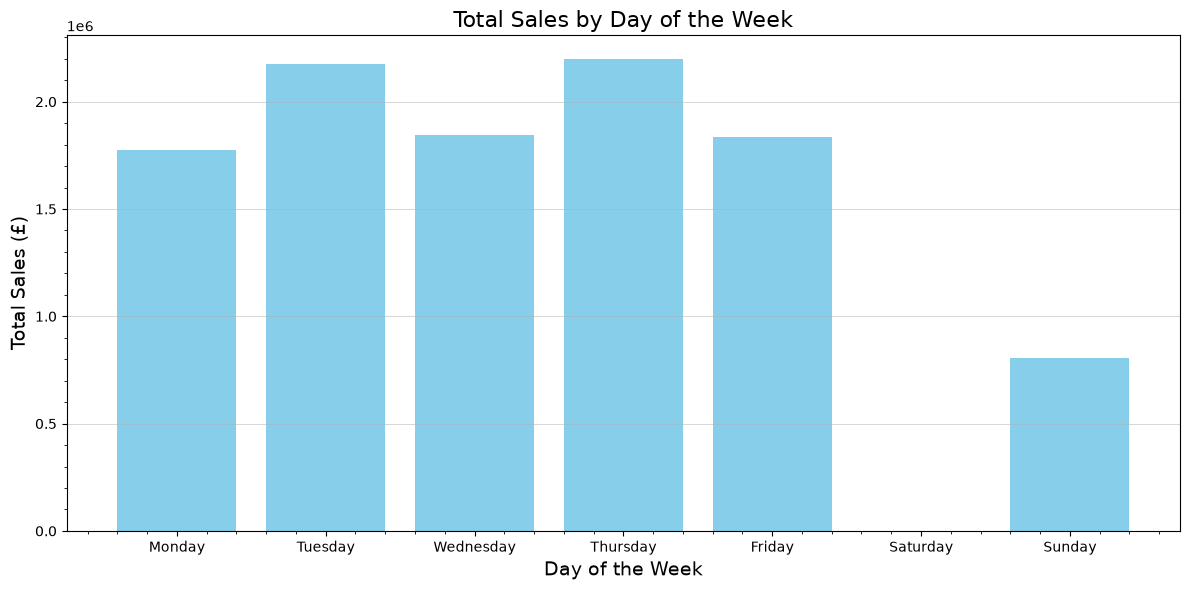

In [26]:
plt.figure(figsize=(12,6))

plt.bar(Day_sales.index,Day_sales.values, color='skyblue')
plt.xlabel("Day of the Week", fontsize=14)
plt.ylabel("Total Sales (£)", fontsize=14)
plt.title("Total Sales by Day of the Week", fontsize=16)
plt.minorticks_on()
plt.grid(axis='y', linestyle='-', linewidth=0.7, alpha=0.5)
plt.tight_layout()
plt.show()

## Sales by Hour

In [27]:
df_clean["HoursOfDay"] = df_clean["InvoiceDate"].dt.hour

Hours_sales = df_clean.groupby("HoursOfDay")["TotalPrice"].sum()
Hours_sales

HoursOfDay
6           4.250
7       31059.210
8      283750.680
9      990054.991
10    1444814.771
11    1236573.290
12    1439324.660
13    1261195.200
14    1177907.521
15    1350333.310
16     752487.960
17     460963.921
18     144603.610
19      50204.950
20      18832.480
Name: TotalPrice, dtype: float64

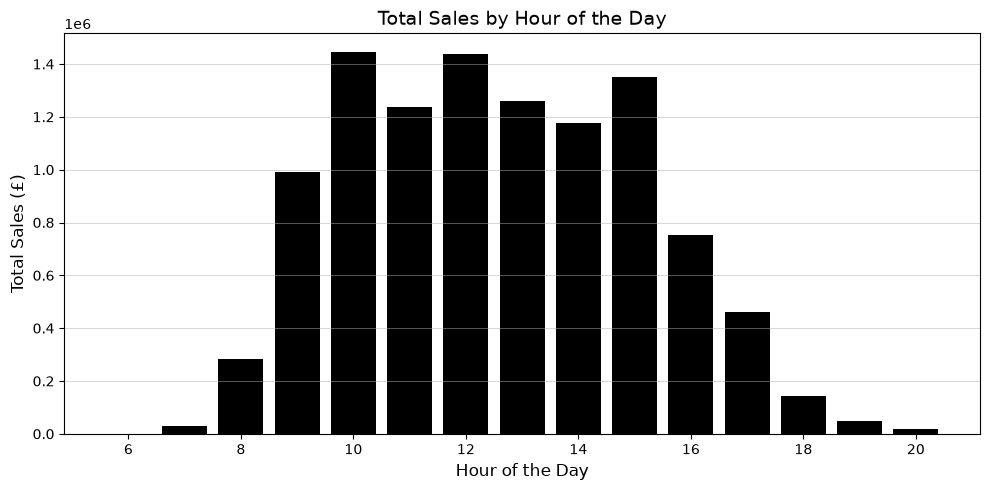

In [28]:
plt.figure(figsize=(10,5))

plt.bar(Hours_sales.index, Hours_sales.values , color = "black")
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Total Sales (£)", fontsize=12)
plt.title("Total Sales by Hour of the Day", fontsize=14)
plt.grid(axis='y', linestyle='-', linewidth=0.7, alpha=0.5)
plt.tight_layout()
plt.show()

## Monthly Orders Analysis

In [29]:
df_clean["MonthSales"] = df_clean["InvoiceDate"].dt.to_period("M")

Monthly_sales = df_clean.groupby("MonthSales")["InvoiceNo"].nunique()

Monthly_sales

MonthSales
2010-12    1629
2011-01    1120
2011-02    1126
2011-03    1531
2011-04    1318
2011-05    1731
2011-06    1576
2011-07    1540
2011-08    1407
2011-09    1896
2011-10    2129
2011-11    2884
2011-12     839
Freq: M, Name: InvoiceNo, dtype: int64

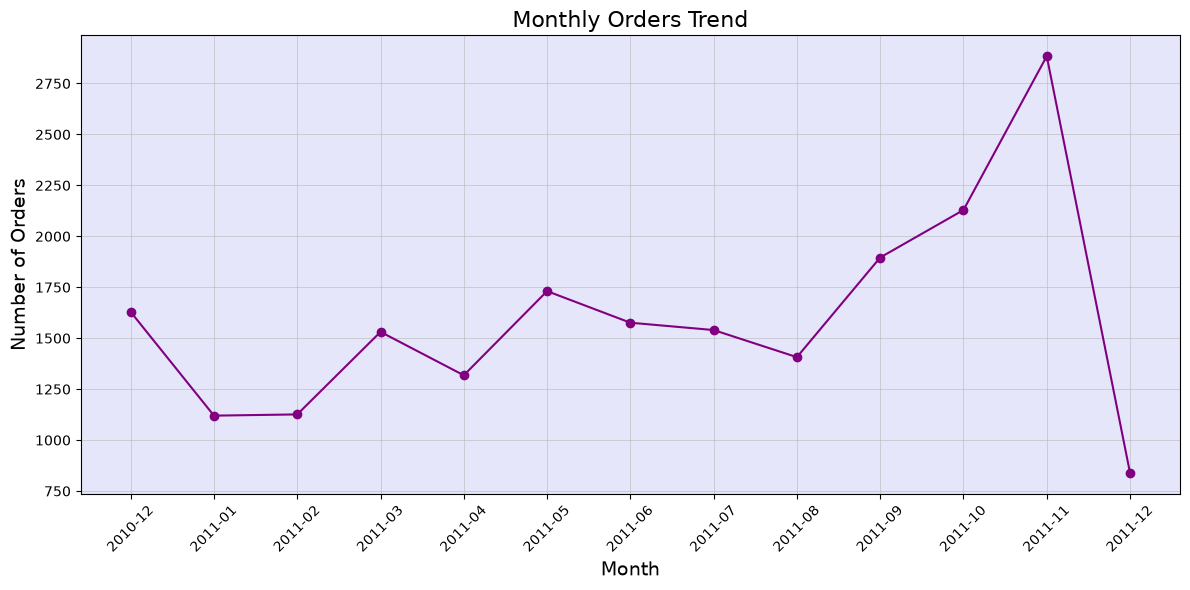

In [30]:
plt.figure(figsize=(12,6))
plt.plot(Monthly_sales.index.astype(str), Monthly_sales.values, marker='o',color="purple")

plt.gca().set_facecolor("lavender")
plt.xlabel("Month", fontsize=14)
plt.ylabel("Number of Orders", fontsize=14)
plt.title("Monthly Orders Trend", fontsize=16)

plt.xticks(rotation=45)
plt.minorticks_off()
plt.grid(which='major', linestyle='-', linewidth=0.7, alpha=0.5)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

## Average Order Value (AOV)

In [31]:
total_sales = df_clean["TotalPrice"].sum()

total_orders = df_clean["InvoiceNo"].nunique()

AOV = total_sales / total_orders

print("Total Sales:", total_sales)
print("Total Orders:", total_orders)
print("Average Order Value:", AOV)



Total Sales: 10642110.804000001
Total Orders: 20726
Average Order Value: 513.4666990253788


The Average Order Value (AOV) is £513.47, indicating that customers spend approximately £513 per order on average.


## Product Quantity Analysis

In [32]:
product_sales = df_clean.groupby("Description")["Quantity"].sum()
top_10_quantities = product_sales.nlargest(10)
top_10_quantities

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48375
WHITE HANGING HEART T-LIGHT HOLDER    37876
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

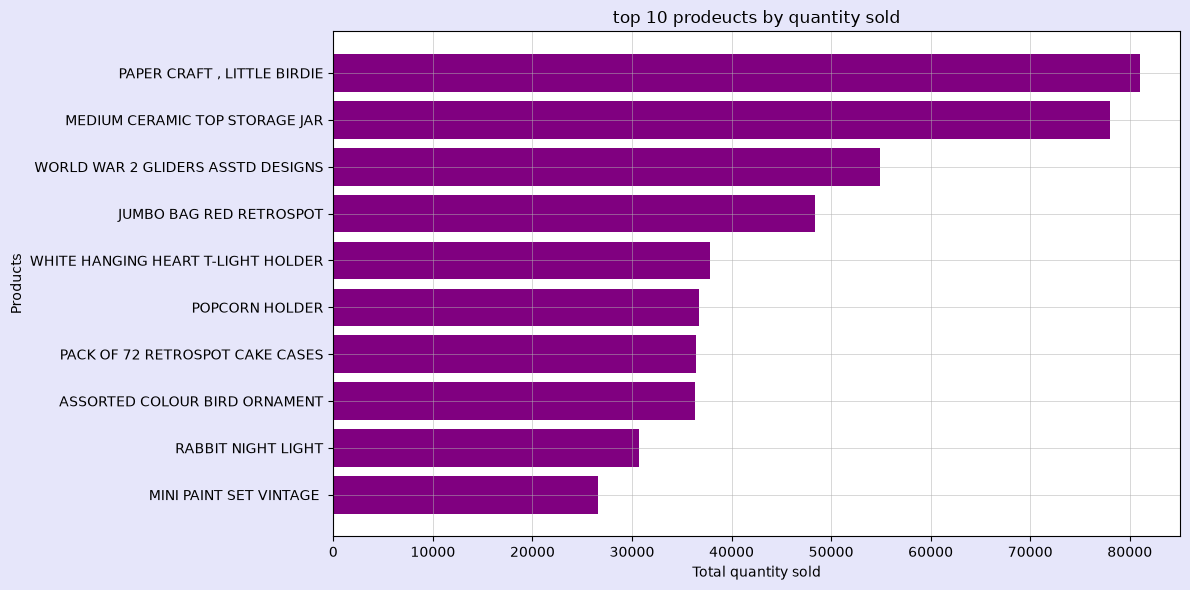

In [33]:
plt.figure(figsize=(12,6),facecolor='lavender')
plt.barh(top_10_quantities.index , top_10_quantities.values , color = 'purple')
plt.xlabel("Total quantity sold")
plt.ylabel("Products")
plt.title("top 10 prodeucts by quantity sold")

plt.gca().invert_yaxis()
plt.minorticks_off()
plt.grid(which="major", linestyle='-' , linewidth=0.7, alpha=0.5)
plt.grid(which="minor" , linestyle='-', linewidth=0.5, alpha=0.3)
plt.tight_layout()
plt.show()

The analysis shows that PAPER CRAFT, LITTLE BIRDIE has the highest quantity sold, followed by MEDIUM CERAMIC TOP STORAGE JAR. This highlights the products with the highest customer demand.


## Sales Distribution Analysis

In [34]:
df_clean["TotalPrice"].describe()

count    526052.000000
mean         20.230150
std         271.391911
min           0.000000
25%           3.900000
50%           9.920000
75%          17.700000
max      168469.600000
Name: TotalPrice, dtype: float64

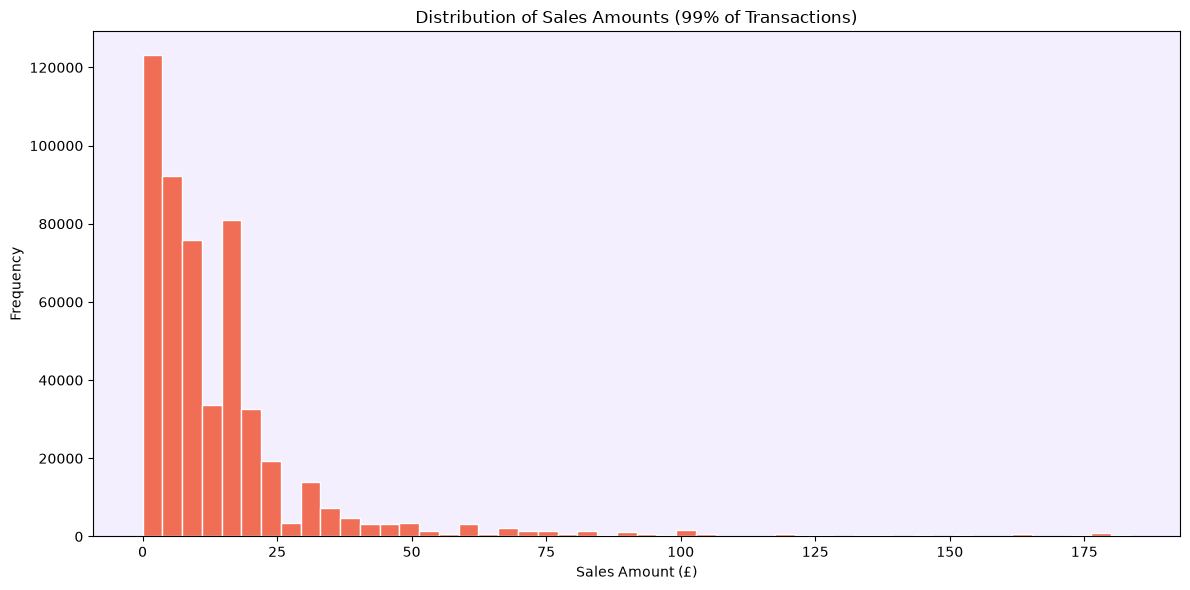

In [35]:
# Exclude extreme values only for visualization
sales_99 = df_clean[df_clean["TotalPrice"] <= df_clean["TotalPrice"].quantile(0.99)]

plt.figure(figsize=(12, 6), facecolor='white')
plt.hist(sales_99["TotalPrice"], bins=50, color="#F06D56", edgecolor='white')

plt.gca().set_facecolor('#F3EFFF')
plt.xlabel("Sales Amount (£)")
plt.ylabel("Frequency")
plt.title("Distribution of Sales Amounts (99% of Transactions)")

plt.tight_layout()
plt.show()

## Correlation Analysis

In [36]:
correlation = df_clean[["Quantity", "UnitPrice", "TotalPrice"]].corr()

correlation

,Quantity,UnitPrice,TotalPrice
Quantity,1.000000,-0.003831,0.898783
UnitPrice,-0.003831,1.000000,0.137396
TotalPrice,0.898783,0.137396,1.000000


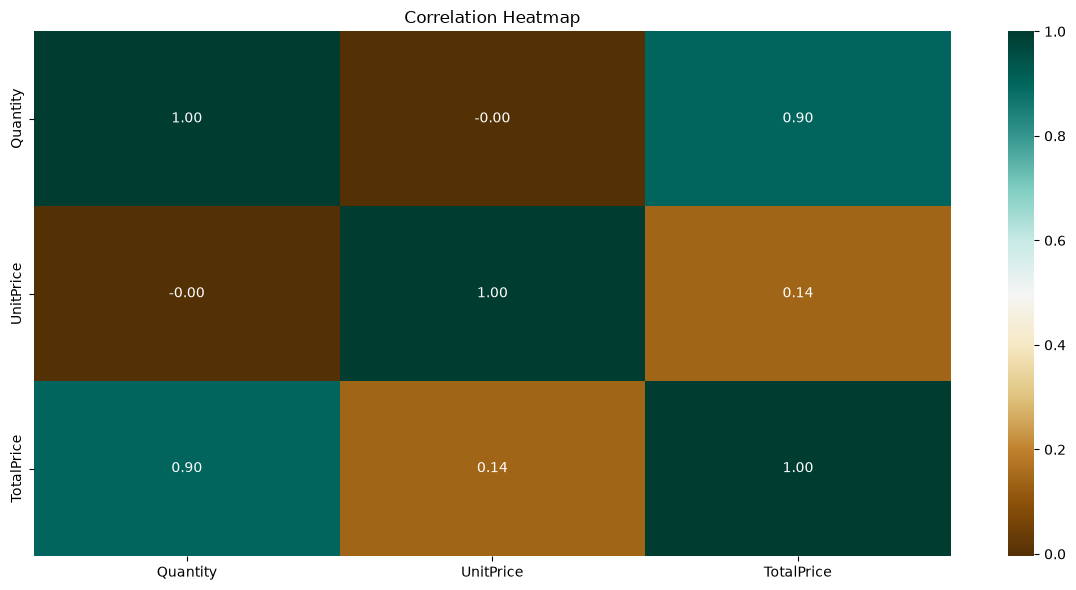

In [37]:
plt.figure(figsize=(12,6))

sns.heatmap(correlation, annot=True, cmap="BrBG", fmt=".2f")

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Customer Segmentation Analysis

Grouping customers based on their purchasing behaviour using RFM (Recency, Frequency, Monetary) analysis.


In [38]:
latest_date = df_clean["InvoiceDate"].max()
latest_date

Timestamp('2011-12-09 12:50:00')

In [40]:
customer_last_purchase = df_clean.groupby("CustomerID")["InvoiceDate"].max()
customer_last_purchase

CustomerID
12346.0   2011-01-18 10:01:00
12347.0   2011-12-07 15:52:00
12348.0   2011-09-25 13:13:00
12349.0   2011-11-21 09:51:00
12350.0   2011-02-02 16:01:00
                  ...        
18280.0   2011-03-07 09:52:00
18281.0   2011-06-12 10:53:00
18282.0   2011-12-02 11:43:00
18283.0   2011-12-06 12:02:00
18287.0   2011-10-28 09:29:00
Name: InvoiceDate, Length: 4339, dtype: datetime64[us]

In [42]:
reference_date = latest_date + pd.Timedelta(days=1)

recency = (reference_date - customer_last_purchase).dt.days
recency

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
          ... 
18280.0    278
18281.0    181
18282.0      8
18283.0      4
18287.0     43
Name: InvoiceDate, Length: 4339, dtype: int64

In [43]:
customer_frequency = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()
customer_frequency

CustomerID
12346.0     1
12347.0     7
12348.0     4
12349.0     1
12350.0     1
           ..
18280.0     1
18281.0     1
18282.0     2
18283.0    16
18287.0     3
Name: InvoiceNo, Length: 4339, dtype: int64

In [44]:
customer_monetary = df_clean.groupby("CustomerID")["TotalPrice"].sum()
customer_monetary

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
             ...   
18280.0      180.60
18281.0       80.82
18282.0      178.05
18283.0     2045.53
18287.0     1837.28
Name: TotalPrice, Length: 4339, dtype: float64

In [45]:
rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": customer_frequency,
    "Monetary": customer_monetary
})

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [48]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1])
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])

In [51]:
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(int).astype(str) +
    rfm["F_Score"].astype(int).astype(str) +
    rfm["M_Score"].astype(int).astype(str)
)

In [52]:
rfm.head()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346.0,326,1,77183.60,1,1,5,115
12347.0,2,7,4310.00,5,5,5,555
12348.0,75,4,1797.24,2,4,4,244
12349.0,19,1,1757.55,4,1,4,414
12350.0,310,1,334.40,1,1,2,112


### Customer Segmentation

Customers are grouped into different segments based on their RFM scores to identify valuable, loyal, and at-risk customers.


In [53]:
import numpy as np

conditions = [
    (rfm["R_Score"].astype(int) >= 4) & (rfm["F_Score"].astype(int) >= 4),
    (rfm["R_Score"].astype(int) <= 2) & (rfm["F_Score"].astype(int) <= 2),
    (rfm["M_Score"].astype(int) >= 4)
]

choices = [
    "Loyal Customers",
    "At-Risk Customers",
    "High-Value Customers"
]

rfm["Customer_Segment"] = np.select(
    conditions,
    choices,
    default="Regular Customers"
)

rfm[["RFM_Score", "Customer_Segment"]].head(10)

,RFM_Score,Customer_Segment
CustomerID,,
12346.0,115,At-Risk Customers
12347.0,555,Loyal Customers
12348.0,244,High-Value Customers
12349.0,414,High-Value Customers
12350.0,112,At-Risk Customers
12352.0,355,High-Value Customers
12353.0,111,At-Risk Customers
12354.0,114,At-Risk Customers
12355.0,112,At-Risk Customers


In [54]:
rfm["Customer_Segment"].value_counts()

Customer_Segment
Regular Customers       1435
Loyal Customers         1139
At-Risk Customers       1065
High-Value Customers     700
Name: count, dtype: int64

## customer segmentation insight

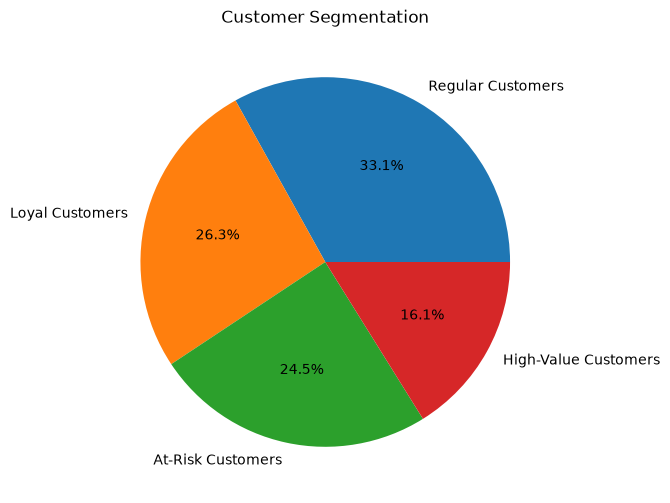

In [64]:
plt.figure(figsize=(10,6))

plt.pie(rfm["Customer_Segment"].value_counts().values, labels=rfm["Customer_Segment"].value_counts().index, autopct='%1.1f%%')
plt.title('Customer Segmentation')
plt.show()

### Customer Segmentation Insights

* **Regular Customers (1,435):** Represent the largest customer segment. Targeted promotions can encourage them to purchase more frequently.
* **Loyal Customers (1,139):** These customers purchase frequently. Loyalty rewards and exclusive offers can help retain them.
* **At-Risk Customers (1,065):** These customers have low recency and frequency scores. Re-engagement campaigns and special discounts may encourage them to return.
* **High-Value Customers (700):** These customers have high monetary scores. Personalized offers and premium services can help maintain their engagement.


## Conclusion

This project analyzed e-commerce sales, customer purchasing patterns, product performance, and customer segments using Python. The insights can help businesses improve sales strategies, understand customer behaviour, and make better data-driven decisions.


In [65]:
df_clean.to_csv("../data/cleaned_online_retail.csv", index=False)

In [1]:
import pandas as pd

df_sql = pd.read_csv("../data/cleaned_online_retail.csv")

df_sql.shape

C:\Users\Mansi Chahar\AppData\Local\Temp\ipykernel_11112\858752000.py:3: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sql = pd.read_csv("../data/cleaned_online_retail.csv")


(526052, 13)

In [7]:
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

connection_url = URL.create(
    "mysql+mysqlconnector",
    username="root",
    password="qwertyuiop",
    host="localhost",
    port=3306,
    database="ecommerce_analytics"
)

engine = create_engine(connection_url)

In [8]:
with engine.connect() as connection:
    print("MySQL Connected Successfully!")

MySQL Connected Successfully!


In [9]:
df_sql.to_sql(
    name="cleaned_online_retail",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=5000
)

526052